# Plot3D

Plot3D files (`&DUMP PLOT3D_QUANTITY`) hold five quantities in the whole domain, written
every `DT_PL3D` seconds. They are the full 3D field, unlike slices.

Run FDS on `fds_data/vort3d_80.fds` first: two meshes, Plot3D output every 10 s.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import fdsreader as fds

sim = fds.Simulation("./fds_data")
print(sim.data_3d.quantities)
print("output times:", sim.data_3d.times)

[Quantity('TEMPERATURE'), Quantity('U-VELOCITY'), Quantity('V-VELOCITY'), Quantity('W-VELOCITY'), Quantity('HRRPUV')]
output times: [10.06 20.11 30.04 40.09 50.  ]


## The whole domain

`get_by_quantity` picks one of the five quantities, `to_global` merges the meshes into one
array `(time, x, y, z)`. With `masked=True` obstructions are filled with `fill`.

In [2]:
temperature = sim.data_3d.get_by_quantity("TEMPERATURE")
data, coords = temperature.to_global(masked=True, fill=np.nan, return_coordinates=True)
print(data.shape, {axis: (float(c[0]), float(c[-1])) for axis, c in coords.items()})

(5, 49, 37, 13) {'x': (-1.0, 11.0), 'y': (-1.0, 8.0), 'z': (0.0, 3.0)}


## Sections through the field

Any plane can be cut out of the array, here a horizontal and a vertical one through the
hottest point at the last output time. Obstructions are blank.

hottest point: x = 9.50 m, y = 6.00 m, z = 0.00 m


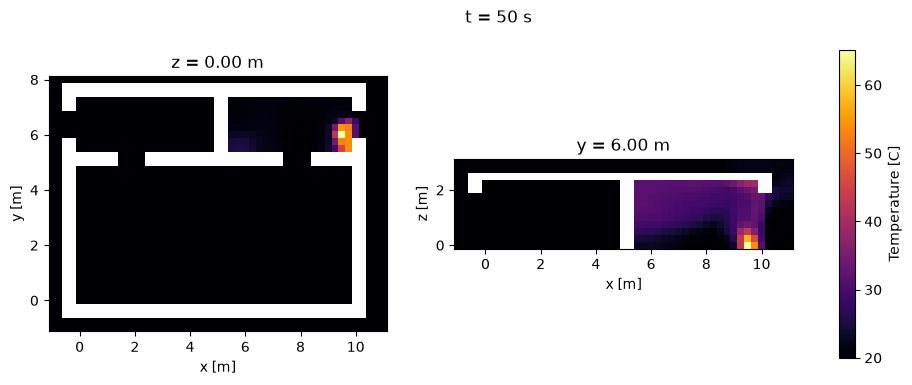

In [3]:
t = -1
ix, iy, iz = np.unravel_index(np.nanargmax(data[t]), data[t].shape)
print(f"hottest point: x = {coords['x'][ix]:.2f} m, y = {coords['y'][iy]:.2f} m, z = {coords['z'][iz]:.2f} m")
vmin, vmax = np.nanmin(data[t]), np.nanmax(data[t])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.pcolormesh(coords["x"], coords["y"], data[t, :, :, iz].T, shading="nearest", vmin=vmin, vmax=vmax, cmap="inferno")
ax1.set(xlabel="x [m]", ylabel="y [m]", title=f"z = {coords['z'][iz]:.2f} m", aspect="equal")
pcm = ax2.pcolormesh(
    coords["x"], coords["z"], data[t, :, iy, :].T, shading="nearest", vmin=vmin, vmax=vmax, cmap="inferno"
)
ax2.set(xlabel="x [m]", ylabel="z [m]", title=f"y = {coords['y'][iy]:.2f} m", aspect="equal")
fig.colorbar(pcm, ax=(ax1, ax2), label="Temperature [C]")
fig.suptitle(f"t = {sim.data_3d.times[t]:.0f} s");

## 3D view

The same array as points in 3D, coloured by temperature and more opaque where it is hotter;
obstructions (NaN) are left out.

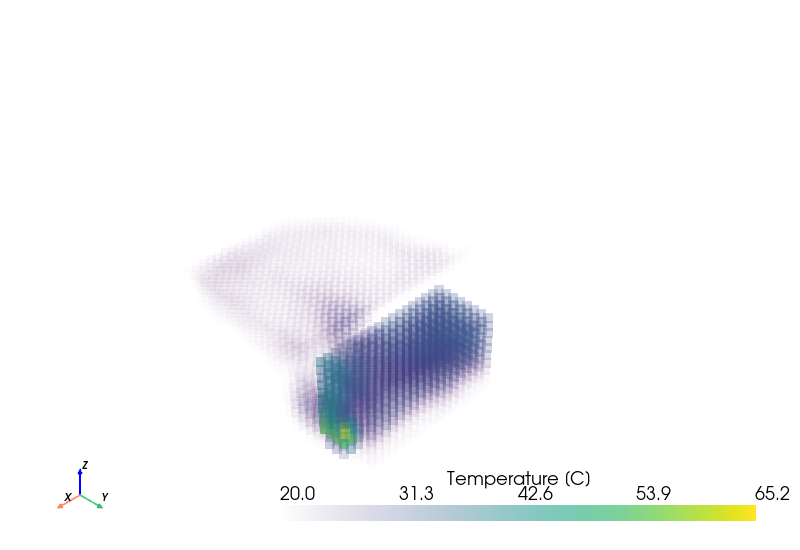

In [4]:
import pyvista as pv

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

x, y, z = np.meshgrid(coords["x"], coords["y"], coords["z"], indexing="ij")
points = pv.PolyData(np.column_stack((x.ravel(), y.ravel(), z.ravel())))
points["temperature"] = data[t].ravel()
points.plot(opacity="linear", nan_opacity=0, point_size=10, scalar_bar_args={"title": "Temperature [C]"})

More in the [API reference](https://fdsreader.readthedocs.io/en/latest/api/pl3d.html).